# Figure 2: matched validation learning curves

This notebook reproduces Figure 2 of the current `MML_CW_Paper.pdf` from the recorded 25%, 50%, and 100% training subsets. Both methods use the same subset rows and fixed validation split. CatBoost points average training seeds 42, 123, and 2026; quadratic logistic regression is deterministic. The paper plots means without error bars.

Matplotlib is building the font cache; this may take a moment.


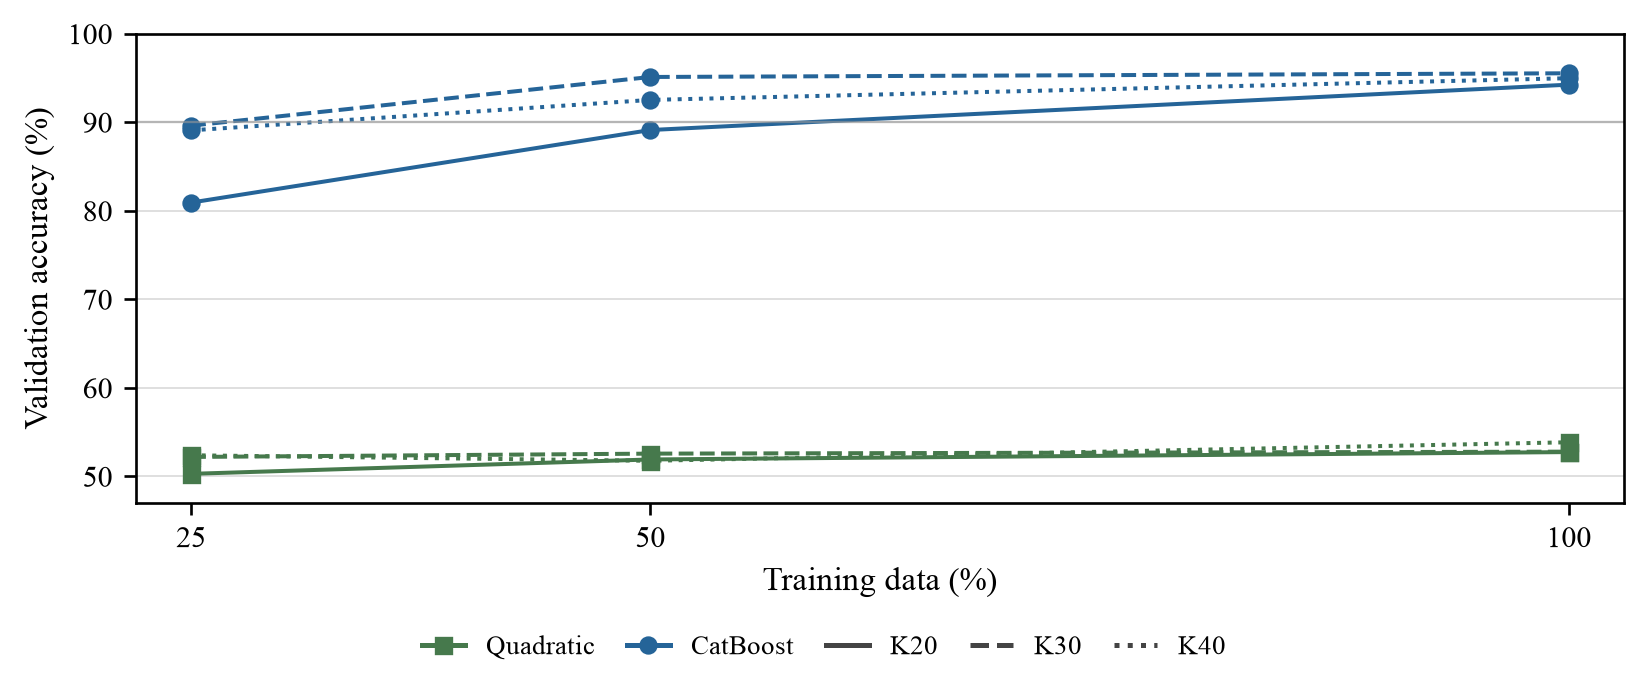

In [1]:
from pathlib import Path
import os, sys
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in (here, *here.parents) if (p / "common.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))
from paper.plot_paper_learning_curve import draw

figure_path, points = draw()
display(Image(filename=str(figure_path)))

In [2]:
for dataset in ("20", "30", "40"):
    quadratic_gain = points[(dataset, "quadratic-logistic", 100)] - points[(dataset, "quadratic-logistic", 25)]
    catboost_gain = points[(dataset, "sign-catboost", 100)] - points[(dataset, "sign-catboost", 25)]
    print(f"K{dataset}: quadratic +{quadratic_gain:.2f} pp; sign-CatBoost +{catboost_gain:.2f} pp")

K20: quadratic +2.46 pp; sign-CatBoost +13.32 pp
K30: quadratic +0.60 pp; sign-CatBoost +5.92 pp
K40: quadratic +1.47 pp; sign-CatBoost +5.89 pp
